# bernacchi2002

Generated by GreenSloth from this model's validations.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mxlpy import scan

In [2]:
import math

import numpy as np
import sympy.physics.units as su
from sympy.physics.units.quantities import Quantity

from mxlpy import Slider, SteadyStateModelBuilder

def _derived_Tk(T_leaf):
    return T_leaf + 273.15

def _derived_gm(gm25, R, c_gm, dHa_gm, dHd_gm, dS_gm, Tk):
    return gm25 * (np.exp((c_gm) - ((dHa_gm) / (R * Tk)))) / (1 + np.exp(((dS_gm * Tk) - (dHd_gm)) / (R * Tk)))

def _derived_Gamma_star(R, c_Gamma_star, dHa_Gamma_star, Tk):
    return np.exp((c_Gamma_star) - ((dHa_Gamma_star) / (R * Tk)))

def _derived_Kc(R, c_Kc, dHa_Kc, Tk):
    return np.exp((c_Kc) - ((dHa_Kc) / (R * Tk)))

def _derived_Ko(R, c_Ko, dHa_Ko, Tk):
    return np.exp((c_Ko) - ((dHa_Ko) / (R * Tk)))

def _derived_Kc_app(R, c_Kc_app, dHa_Kc_app, Tk):
    return np.exp((c_Kc_app) - ((dHa_Kc_app) / (R * Tk)))

def _derived_Ko_app(R, c_Ko_app, dHa_Ko_app, Tk):
    return np.exp((c_Ko_app) - ((dHa_Ko_app) / (R * Tk)))

def _derived_Vcmax(Vcmax25, R, c_Vcmax, dHa_Vcmax, Tk):
    return Vcmax25 * np.exp((c_Vcmax) - ((dHa_Vcmax) / (R * Tk)))

def _derived_Rd(Rd25, R, c_Rd, dHa_Rd, Tk):
    return Rd25 * np.exp((c_Rd) - ((dHa_Rd) / (R * Tk)))

def _derived_Km(O, Kc, Ko):
    return Kc * (1 + (O) / (Ko))

def _derived_A(Ci, gm, Gamma_star, Vcmax, Rd, Km):
    return (- (((Vcmax) - (Rd)) / (gm) + Ci + Km) + np.pow(((((Vcmax) - (Rd)) / (gm) + Ci + Km) ** (2)) - (4 * (-1) / (gm) * ((Rd * (Ci + Km)) - (Vcmax * ((Ci) - (Gamma_star))))), 1 / 2)) / (2 * (-1) / (gm))

def _derived_Cc(Ci, gm, A):
    return (Ci) - ((A) / (gm))

def _derived_A_inf(Ci, Gamma_star, Vcmax, Rd, Km):
    return ((Vcmax * ((Ci) - (Gamma_star))) / (Ci + Km)) - (Rd)

def _derived_l_gm(A, A_inf):
    return ((A_inf) - (A)) / (A_inf)

def get_model() -> SteadyStateModelBuilder:
    m = SteadyStateModelBuilder()
    m.add_parameter("Ci", 250, unit=0.000001, display_name="Ci", tex_name="C_i", slider=Slider(min="10", max="1600", step="5"))
    m.add_parameter("O", 210, unit=0.001, display_name="O", tex_name="O", slider=Slider(min="0", max="400", step="5"))
    m.add_parameter("T_leaf", 25, unit=Quantity("celsius", abbrev="°C"), display_name="T_leaf", tex_name="T_{leaf}", slider=Slider(min="5", max="45", step="0.5"))
    m.add_parameter("gm25", 0.095, unit=su.mol/(su.meter**2*su.second*su.bar), display_name="gm25", tex_name="g_{m,25}", slider=Slider(min="0.01", max="1", step="0.005"))
    m.add_parameter("Vcmax25", 21.1, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Vcmax25", tex_name="V_{c,max,25}", slider=Slider(min="0", max="200", step="0.5"))
    m.add_parameter("Rd25", 0, unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Rd25", tex_name="R_{d,25}", slider=Slider(min="0", max="5", step="0.01"))
    m.add_parameter("R", 0.008314, unit=su.joule*su.kilo/(su.kelvin*su.mol), tex_name="R")
    m.add_parameter("c_gm", 20, unit=None, tex_name="c_{g_m}")
    m.add_parameter("dHa_gm", 49.6, unit=su.joule*su.kilo/su.mol, tex_name="\\Delta H_{a,g_m}")
    m.add_parameter("dHd_gm", 437.4, unit=su.joule*su.kilo/su.mol, tex_name="\\Delta H_{d,g_m}")
    m.add_parameter("dS_gm", 1.4, unit=su.joule*su.kilo/(su.kelvin*su.mol), tex_name="\\Delta S_{g_m}")
    m.add_parameter("c_Gamma_star", 13.49, unit=None, tex_name="c_{\\Gamma^*}")
    m.add_parameter("dHa_Gamma_star", 24.46, unit=su.joule*su.kilo/su.mol, tex_name="\\Delta H_{a,\\Gamma^*}")
    m.add_parameter("c_Kc", 38.28, unit=None, tex_name="c_{K_c}")
    m.add_parameter("dHa_Kc", 80.99, unit=su.joule*su.kilo/su.mol, tex_name="\\Delta H_{a,K_c}")
    m.add_parameter("c_Ko", 14.68, unit=None, tex_name="c_{K_o}")
    m.add_parameter("dHa_Ko", 23.72, unit=su.joule*su.kilo/su.mol, tex_name="\\Delta H_{a,K_o}")
    m.add_parameter("c_Kc_app", 38.05, unit=None, tex_name="c_{K_{c,app}}")
    m.add_parameter("dHa_Kc_app", 79.43, unit=su.joule*su.kilo/su.mol, tex_name="\\Delta H_{a,K_{c,app}}")
    m.add_parameter("c_Ko_app", 20.3, unit=None, tex_name="c_{K_{o,app}}")
    m.add_parameter("dHa_Ko_app", 36.38, unit=su.joule*su.kilo/su.mol, tex_name="\\Delta H_{a,K_{o,app}}")
    m.add_parameter("c_Vcmax", 26.35, unit=None, tex_name="c_{V_{c,max}}")
    m.add_parameter("dHa_Vcmax", 65.33, unit=su.joule*su.kilo/su.mol, tex_name="\\Delta H_{a,V_{c,max}}")
    m.add_parameter("c_Rd", 18.72, unit=None, tex_name="c_{R_d}")
    m.add_parameter("dHa_Rd", 46.39, unit=su.joule*su.kilo/su.mol, tex_name="\\Delta H_{a,R_d}")
    m.add_derived("Tk", _derived_Tk, args=["T_leaf"], unit=su.kelvin, tex_name="T_k")
    m.add_derived("gm", _derived_gm, args=["gm25", "R", "c_gm", "dHa_gm", "dHd_gm", "dS_gm", "Tk"], unit=su.mol/(su.meter**2*su.second*su.bar), display_name="gm", tex_name="g_m")
    m.add_derived("Gamma_star", _derived_Gamma_star, args=["R", "c_Gamma_star", "dHa_Gamma_star", "Tk"], unit=0.000001, display_name="Gamma_star", tex_name="\\Gamma^*")
    m.add_derived("Kc", _derived_Kc, args=["R", "c_Kc", "dHa_Kc", "Tk"], unit=0.000001, display_name="Kc", tex_name="K_c")
    m.add_derived("Ko", _derived_Ko, args=["R", "c_Ko", "dHa_Ko", "Tk"], unit=0.001, display_name="Ko", tex_name="K_o")
    m.add_derived("Kc_app", _derived_Kc_app, args=["R", "c_Kc_app", "dHa_Kc_app", "Tk"], unit=0.000001, display_name="Kc_app", tex_name="K_{c,app}")
    m.add_derived("Ko_app", _derived_Ko_app, args=["R", "c_Ko_app", "dHa_Ko_app", "Tk"], unit=0.001, display_name="Ko_app", tex_name="K_{o,app}")
    m.add_derived("Vcmax", _derived_Vcmax, args=["Vcmax25", "R", "c_Vcmax", "dHa_Vcmax", "Tk"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Vcmax", tex_name="V_{c,max}")
    m.add_derived("Rd", _derived_Rd, args=["Rd25", "R", "c_Rd", "dHa_Rd", "Tk"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="Rd", tex_name="R_d")
    m.add_derived("Km", _derived_Km, args=["O", "Kc", "Ko"], unit=0.000001, display_name="Km", tex_name="K_m")
    m.add_derived("A", _derived_A, args=["Ci", "gm", "Gamma_star", "Vcmax", "Rd", "Km"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="A", tex_name="A")
    m.add_derived("Cc", _derived_Cc, args=["Ci", "gm", "A"], unit=0.000001, display_name="Cc", tex_name="C_c")
    m.add_derived("A_inf", _derived_A_inf, args=["Ci", "Gamma_star", "Vcmax", "Rd", "Km"], unit=su.mol*su.micro/(su.meter**2*su.second), display_name="A_inf", tex_name="A_{\\infty}")
    m.add_derived("l_gm", _derived_l_gm, args=["A", "A_inf"], unit=None, display_name="l_gm", tex_name="l_{g_m}")
    return m


## Figure 1: temperature response of gm, normalised to 25 °C

In [3]:
tables = {}

# Scan t
to_scan = pd.DataFrame({"T_leaf": np.linspace(10, 40, 301), "gm25": 1})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["gm"]].isna().any(axis=None)
tables["t"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "gm": frame["gm"].to_numpy(),
}

  0%|          | 0/301 [00:00<?, ?it/s]

100%|██████████| 301/301 [00:00<00:00, 3785.08it/s]

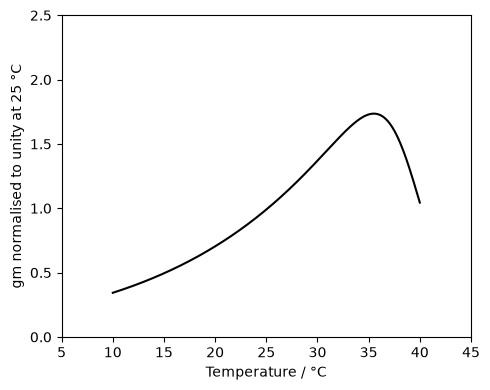

In [4]:
fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(5, 4), squeeze=False)
ax0 = axs[0, 0]
ax0.plot(tables["t"]["x"], tables["t"]["gm"], color="black")
ax0.set_xlabel("Temperature / °C")
ax0.set_ylabel("gm normalised to unity at 25 °C")
ax0.set_xlim(5, 45)
ax0.set_ylim(0, 2.5)
plt.tight_layout()
plt.show()

## Figure 2: Γ*, Kc and Ko on a Cc basis (dashed) and apparent (solid)

In [5]:
data = {"T":[25],"Kc":[260],"Ko":[178]}
data = {k: np.array(c) for k, c in data.items()}
tables = {}

# Scan t
to_scan = pd.DataFrame({"T_leaf": np.linspace(5, 45, 401)})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Gamma_star"]].isna().any(axis=None)
tables["t"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "Gamma_star": frame["Gamma_star"].to_numpy(),
}

# Scan k
to_scan = pd.DataFrame({"T_leaf": np.linspace(10, 40, 301)})
result = scan.steady_state(
    get_model(),
    to_scan=to_scan,
)
frame = result.combined
assert not frame[["Kc","Kc_app","Ko","Ko_app"]].isna().any(axis=None)
tables["k"] = {
    "x": to_scan["T_leaf"].to_numpy(),
    "Kc": frame["Kc"].to_numpy(),
    "Kc_app": frame["Kc_app"].to_numpy(),
    "Ko": frame["Ko"].to_numpy(),
    "Ko_app": frame["Ko_app"].to_numpy(),
}

  0%|          | 0/401 [00:00<?, ?it/s]

 78%|███████▊  | 314/401 [00:00<00:00, 3131.22it/s]

100%|██████████| 401/401 [00:00<00:00, 3184.18it/s]

  0%|          | 0/301 [00:00<?, ?it/s]

100%|██████████| 301/301 [00:00<00:00, 3480.03it/s]

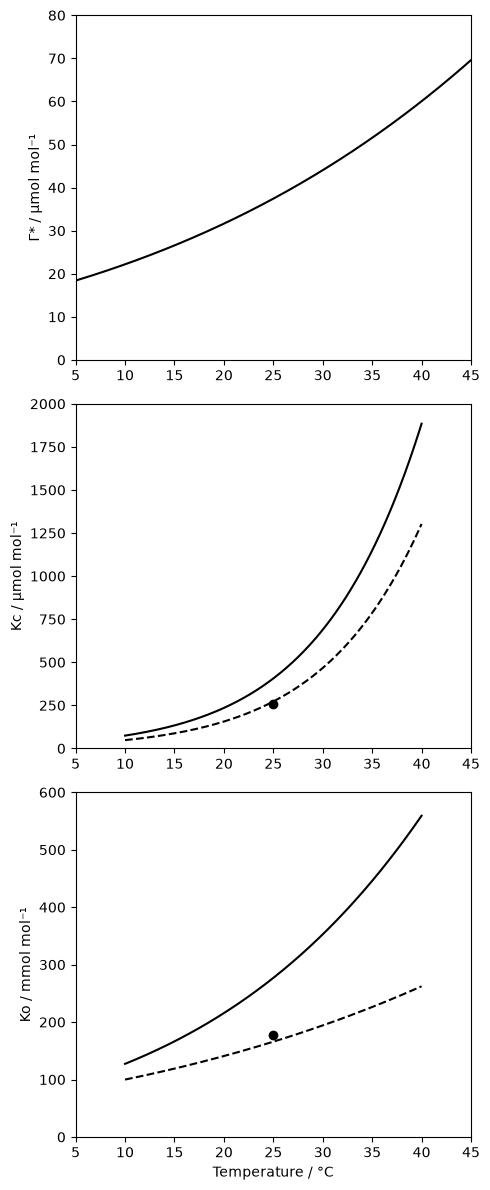

In [6]:
fig, axs = plt.subplots(nrows=3, ncols=1, figsize=(5, 12), squeeze=False)
ax0 = axs[0, 0]
ax0.plot(tables["t"]["x"], tables["t"]["Gamma_star"], color="black")
ax0.set_ylabel("Γ* / µmol mol⁻¹")
ax0.set_xlim(5, 45)
ax0.set_ylim(0, 80)
ax1 = axs[1, 0]
ax1.plot(tables["k"]["x"], tables["k"]["Kc_app"], color="black")
ax1.plot(tables["k"]["x"], tables["k"]["Kc"], color="black", ls="--")
ax1.plot(data["T"], data["Kc"], color="black", ls="none", marker="o")
ax1.set_ylabel("Kc / µmol mol⁻¹")
ax1.set_xlim(5, 45)
ax1.set_ylim(0, 2000)
ax2 = axs[2, 0]
ax2.plot(tables["k"]["x"], tables["k"]["Ko_app"], color="black")
ax2.plot(tables["k"]["x"], tables["k"]["Ko"], color="black", ls="--")
ax2.plot(data["T"], data["Ko"], color="black", ls="none", marker="o")
ax2.set_xlabel("Temperature / °C")
ax2.set_ylabel("Ko / mmol mol⁻¹")
ax2.set_xlim(5, 45)
ax2.set_ylim(0, 600)
plt.tight_layout()
plt.show()